# Simulated Examples

This notebook demonstrates both the BART_SURVIVAL package `simulation` and `suv_bart` modules.

The `simulation` module will be used to generate simulated Survival type datasets and `surv_bart` will be used to complete the Survival analyses. 

The `scikit-survival` package will be used to addionally for comparison and to complete some additional metric evaluations.

The raw `.ipynb` file can be found in the `examples` directory in the github repository.

# NOTE:
Throughout the notebook survival is commonly denoted by `sv` as a singular term or as a prefix/suffix. For example an object listed as `sv_prob` would indicated "survival probability". 

In [20]:
# pip install --upgrade bart_survival
# !pip install scikit-survival
# !pip install notebook

In [ ]:
import numpy as np
import sksurv as sks
from bart_survival import surv_bart as sb 
from bart_survival import simulation as sm
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

## Generate Simulation Matrix 

A covariate matrix is generated below. A few key parameters include:
- `N` = number of observations
- `x_vars` = number of covariates
- `VAR_CLASS` = list containing the upper range of the covariate values.
    - Each covariate is drawn from a uniform distribution with the lower bound == 0 and upper bound == VAR_CLASS[i].
    - VAR_CLASS == 2 is a reserved for generating a binary variable [values == 0,1]. The distribution of the binary variables is set by VAR_PROB.
- `VAR_PROB` = None for all VAR_CLASS != 2 and a probability value for VAR_CLASS == 2.
- `rng` = numpy random number generator. 
    - If not set rng will reset with each call to get_x_matrix.

If `len(VAR_CLASS)` is less than `x_vars` the covariate matrix will be filled with uniform(0,1) covariates up to size of `x_vars`

In [4]:
rng = np.random.default_rng(1)

# create the covariate matrix
# - 100 obs, 5 vars, [binary, binary, 0-5, 0-1, 0-1]
x_mat = sm.get_x_matrix(
    N=1000,
    x_vars=5,
    VAR_CLASS=[2,2,1],
    VAR_PROB=[.5, .7, None],
    rng = rng
)

x_mat[0:10,:]

array([[1.        , 1.        , 0.284     , 0.11526701, 0.68893629],
       [1.        , 0.        , 0.01      , 0.87859741, 0.53159136],
       [0.        , 0.        , 0.11      , 0.29933889, 0.74260155],
       [1.        , 1.        , 0.131     , 0.74592912, 0.89760035],
       [0.        , 1.        , 0.432     , 0.93736634, 0.45782069],
       [0.        , 1.        , 0.776     , 0.35489974, 0.03277996],
       [1.        , 1.        , 0.404     , 0.93135644, 0.76689895],
       [0.        , 1.        , 0.146     , 0.88222506, 0.45901483],
       [1.        , 0.        , 0.168     , 0.12161778, 0.7825713 ],
       [0.        , 1.        , 0.953     , 0.12783193, 0.85355997]])

Returned is a 2d ndarray. 

If a more complex covariate matrix is needed, it can be constructed outside of this function and passed to the simulation step.

## Generate Survival Simulation

Using the covariate matrix `x_mat`, simulated survival data can be generated using `simulate_survival()`

`simulate_survival` uses a 2-parameter weibull distribution to generate both:
- simulated event times
- true Survival probabilities and hazard rates

The two parameters required are a the `scale_f` and `shape_f`. Both are formatted as `str` type equation that is evaluated to produce the simulation and true survival components.

By using both scale and shape, a variety of Survival settings can be simulated including proportional hazards and non-proportional hazards (when `shape_f` incorporates the covariate matrix).

- `scale_f` 
  
  In form "np.exp($B_0$ + $B_1$ * x_mat[:,0] + ... + $B_N$ * x_mat[:,N])"
    
    The linear equation must be contained in an $exp()$, which is necessary for the parameterization of the Weibull distribution.

    When resolved, a larger scale value will result in a shrunk Survival curve and a smaler scale value will result in a stretched Survival curve.

- `shape_f`
  
  In form "A"; where A is any real number. 

  Or form "A + $A_N$ * x_mat[:,N] + ..." 

  When shape_f > 1 the Hazard rate will increase.
  When shape_f < 1 the Hazaard rate will decrease.
  When shape_f == 1 then the Hazard rate is constant and the Weibull distribution resolves to an Exponential function.

  When shape_f includes "x_mat", then the resulting Survival curves will not follow the assumption of proportional hazards.

- `eos`  

  Allows the simulated Survival times and true Survival curves to be truncated at the EOS time point.

- `cens_scale`

  Allows incorporation of censoring at random.

- `time_scale`

  Allows reduction of time series by a factor of the provided value. 

  So time series [1,2,3,4,5,6,8,9,10] w/ `time_scale=2` will resolve to [2,4,6,8,10]. 

  This becomes relevant when completing the Survival analyses. The algorithm evaluates all time points in the series up to the event time, which can be computationaly heavy. Reducing the time series by a scaling factor reduces this burden. The surv_bart module has additional functionality for scaling the time-series.

Covariates not included in the `scale_f` equation will have no impact on the outcome
    



In [5]:
event_dict, sv_true, sv_scale_true = sm.simulate_survival(
    x_mat = x_mat,
    scale_f = "np.exp(4 + .4*x_mat[:,0] + .1*x_mat[:,1] + .01*x_mat[:,2])", # note that x_mat[:,3] and x_mat[:,4] are not included
    shape_f = "1", # hazard is constant
    eos = 180,
    cens_scale=None,
    time_scale=60,
    true_only=False,
    rng = rng
)

mean shape 1.0
mean scale 73.33053395906819
mean time draws 70.07190944565642


In [6]:
np.exp(.4)
np.exp(.2)
np.exp(.1)
# np.log(1.5)

np.float64(1.1051709180756477)

The simulated Survival data can be accessed by `event_dict`

In [7]:
print("Time of event")
print(event_dict["t_event"][0:5])
print("Status at event time")
print(event_dict["status"][0:5])

print("Scaled event times")
print(event_dict["t_event_scale"][0:5])

Time of event
[[180.]
 [ 26.]
 [132.]
 [180.]
 [ 28.]]
Status at event time
[[0.]
 [1.]
 [1.]
 [0.]
 [1.]]
Scaled event times
[[3.]
 [1.]
 [3.]
 [3.]
 [1.]]


The actual Survival data can be accessed through `sv_true` and `sv_true_scale`.

A plot of the actual survival curves is shown below. 
These curves are what will be predicted by the survival analyses

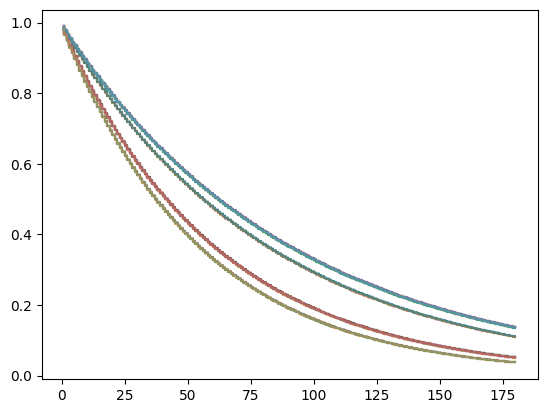

In [8]:
N = sv_true["sv_true"].shape[0]
for i in range(0,100):
    plt.step(sv_true["true_times"], sv_true["sv_true"][i,:], alpha=0.3)

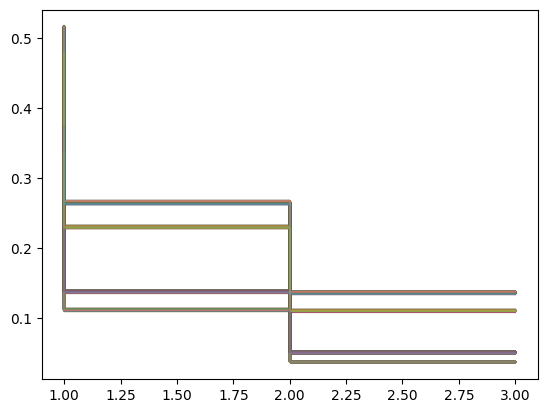

In [9]:

N = sv_scale_true["sv_true"].shape[0]
for i in range(0,N):
    plt.step(sv_scale_true["scale_times"], sv_scale_true["sv_true"][i,:], alpha=0.3)

## Survival Analyses

### Data Prep

The data needs to be transformed to a specific format, denoted as long-time form, to work for analyses.

The long-time form changes the representation from a single-time/event per observation into a set of time/event obeservations for each time-point upto the observed time.

This transformation can be completed with the pre-processing step `get_surv_pre_train`, which takes a vector for the observed event times, a vector for the corresponding event status, a corresponding matrix of covariates.

This time expansion can lead to an exceptionally large dataset. For example a dataset with 100 observations, but the follow-up time is 5 years would lead to an expanded dataset approaching 180,000 rows of data. 

To reduce this expansion it is recommended to downscale the observed times. In the 5 year study, it may only be necessary to generate a model for the five year-end time points. So an appropriate scaling factor would be 365 days. 

This is adjusted in the `get_surv_pre_train` method w/ the `time_scale` parameter. 

In [10]:
# prepare data
# t_scale = sb.get_time_transform(event_dict["t_event"], time_scale = 60)
# y_sk = sb.get_y_sklearn(event_dict["status"], t_scale)
# trn = sb.get_surv_pre_train(y_sk, x_mat, weight=None)
# post_test = sb.get_posterior_test(y_sk=y_sk, x_test = x_mat)

trn = sb.get_surv_pre_train(
    y_time = event_dict["t_event"],
    y_status= event_dict["status"],
    x = x_mat,
    time_scale=60
)

post_test = sb.get_posterior_test(
    y_time=event_dict["t_event"], 
    y_status=event_dict["status"],
    x = x_mat,
    time_scale=60
    )
    

In [11]:
print(trn.keys())
print(post_test.keys())

dict_keys(['y', 'x', 'w', 'coord'])
dict_keys(['post_x', 'coords'])


In [12]:
trn["x"].shape

(1589, 6)

### Train Model

The `BartSurvModel` contains the model. To initiate the class/model, two configuration parameters must be provided.

1. `model_config` 
    
    set of parameters specific to the BART model
    
    - `trees` is the number of trees to generate
    - `split_rules` defines the type of data in each covariate
      - the split rules should be ordered in the order of the covariates
      - time is the first covariate and will always be "pmb.ContinuousSplitRule()"
      - OneHotSplitRule is used for categorical variables
      - ContinuousSplitRule is used for continuous variables

2. `sample_config`

    set of parameters specific to the Sampling procedure


In [14]:
SPLIT_RULES =  [
    "pmb.ContinuousSplitRule()", # time
    "pmb.OneHotSplitRule", # x_mat[:,0]
    "pmb.OneHotSplitRule", # x_mat[:,1]
    "pmb.ContinuousSplitRule()", # x_mat[:,2]
    "pmb.ContinuousSplitRule()", # x_mat[:,3]
    "pmb.ContinuousSplitRule()", # x_mat[:,4]
]

model_dict = {"trees": 40,
    "split_rules": SPLIT_RULES
}
sampler_dict = {
            "draws": 500,
            "tune": 500,
            "cores": 4,
            "chains": 4,
            "compute_convergence_checks": False
        }

BSM = sb.BartSurvModel(model_config=model_dict, sampler_config=sampler_dict)

The model can be trained with `.fit()`

All components to train the model should be contained in the dict `trn` (output of get_surv_pre_train)

In [15]:
BSM.fit(
    y =  trn["y"],
    X = trn["x"],
    weights=trn["w"],
    coords = trn["coord"],
    random_seed=5
)

Multiprocess sampling (4 chains in 4 jobs)
FastSurvMHBART: [trees]


Output()

Sampling 4 chains for 500 tune and 500 draw iterations (2_000 + 2_000 draws total) took 2 seconds.


<xarray.DataTree>
Group: /
│   Attributes:
│       id:              12560fb3743544a2
│       model_type:      BART_Survival
│       version:         0.1
│       sampler_config:  {"draws": 500, "tune": 500, "cores": 4, "chains": 4, "co...
│       model_config:    {"trees": 40, "split_rules": ["pmb.ContinuousSplitRule()...
├── Group: /posterior
│       Dimensions:      (chain: 4, draw: 500, trees_dim_0: 1)
│       Coordinates:
│         * chain        (chain) int64 32B 0 1 2 3
│         * draw         (draw) int64 4kB 0 1 2 3 4 5 6 ... 493 494 495 496 497 498 499
│         * trees_dim_0  (trees_dim_0) int64 8B 0
│       Data variables:
│           trees        (chain, draw, trees_dim_0) float64 16kB 0.0 0.0 0.0 ... 0.0 0.0
│       Attributes:
│           created_at:                 2026-07-06T16:00:33.911554+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.1.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.0.0
│           sample_dims:                ['chain', 'draw']
│           sampling_time:              1.5746641159057617
│           tuning_steps:               500
├── Group: /sample_stats
│       Dimensions:                   (chain: 4, draw: 20000, T_trees_dim_0: 255,
│                                      V_trees_dim_0: 255, F_trees_dim_0: 255,
│                                      L_trees_dim_0: 255, node_counts_dim_0: 40,
│                                      R_trees_dim_0: 255, variable_inclusion_dim_0: 6)
│       Coordinates:
│         * chain                     (chain) int64 32B 0 1 2 3
│         * draw                      (draw) int64 160kB 0 1 2 3 ... 19997 19998 19999
│         * T_trees_dim_0             (T_trees_dim_0) int64 2kB 0 1 2 3 ... 252 253 254
│         * V_trees_dim_0             (V_trees_dim_0) int64 2kB 0 1 2 3 ... 252 253 254
│         * F_trees_dim_0             (F_trees_dim_0) int64 2kB 0 1 2 3 ... 252 253 254
│         * L_trees_dim_0             (L_trees_dim_0) int64 2kB 0 1 2 3 ... 252 253 254
│         * node_counts_dim_0         (node_counts_dim_0) int64 320B 0 1 2 ... 37 38 39
│         * R_trees_dim_0             (R_trees_dim_0) int64 2kB 0 1 2 3 ... 252 253 254
│         * variable_inclusion_dim_0  (variable_inclusion_dim_0) int64 48B 0 1 2 3 4 5
│       Data variables:
│           T_trees                   (chain, draw, T_trees_dim_0) float32 82MB 0.893...
│           V_trees                   (chain, draw, V_trees_dim_0) float32 82MB -0.17...
│           F_trees                   (chain, draw, F_trees_dim_0) int16 41MB 2 ... -1
│           L_trees                   (chain, draw, L_trees_dim_0) int16 41MB 1 3 ... -1
│           node_counts               (chain, draw, node_counts_dim_0) float32 13MB 7...
│           R_trees                   (chain, draw, R_trees_dim_0) int16 41MB 2 4 ... -1
│           variable_inclusion        (chain, draw, variable_inclusion_dim_0) float64 4MB ...
│       Attributes:
│           created_at:                 2026-07-06T16:00:34.007777+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.1.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.0.0
│           sample_dims:                ['chain', 'draw']
│           sampling_time:              1.5746641159057617
│           tuning_steps:               500
└── Group: /observed_data
        Dimensions:    (obs_dim_0: 1589, obs_dim_1: 1)
        Coordinates:
          * obs_dim_0  (obs_dim_0) int64 13kB 0 1 2 3 4 5 ... 1584 1585 1586 1587 1588
          * obs_dim_1  (obs_dim_1) int64 8B 0
        Data variables:
            obs        (obs_dim_0, obs_dim_1) int64 13kB 0 0 0 1 0 0 1 ... 1 1 1 0 1 0 1
        Attributes:
            created_at:                 2026-07-06T16:00:34.028310+00:00
            creation_library:           ArviZ
            creation_

Updated 2026:

The model object is returned as a series of tree objects. Which is here represented by a trees in a matrix space representation.

BART does not provide coefficients from the trained model, like seen in linear regression or a Cox model. 

Instead in the context of survival, posterior predictions must be collected to evaluate the model.

This is completed using `sample_posterior_predictive()` and the `post_test` datasets.



In [ ]:
post1 = BSM.sample_posterior_predictive(X_pred=post_test["post_x"], coords=post_test["coords"])

0.19928601491078082
Starting predict ...
Processing: 3000 observations, 2000 thinned draws (Thin factor: 1)...


In [18]:
post1

array([[0.44012424, 0.412415  , 0.44168787, ..., 0.4704472 , 0.44242315,
        0.47202414],
       [0.43868209, 0.41618759, 0.43349243, ..., 0.46899243, 0.44624749,
        0.46375383],
       [0.41755215, 0.39531044, 0.41241477, ..., 0.50358039, 0.4807107 ,
        0.49832319],
       ...,
       [0.55709497, 0.45829313, 0.50516639, ..., 0.42506645, 0.42730482,
        0.24744026],
       [0.56031741, 0.46153452, 0.50842374, ..., 0.41159663, 0.41381937,
        0.23666922],
       [0.54332361, 0.47075266, 0.51767026, ..., 0.39579836, 0.42372435,
        0.24456236]])

`post1` is a series of observation\*time probability values predicted for each observation\*time combination. Sets of these values are collected from draws during the sampling procudure, providing the probability distribution of the value.

`post1` is not yet the Survival probability. It is more similar to the hazard rate, but it is not exactly interpreted as a hazard rate (since it is a probability).

The Survival probability can further be derived with `get_sv_prob()`
- `sv_prob` variable contains the Survival probability and the mu (hazard-like) probability. 
- Each array is formatted with the dimension:
  
  (draw, obs, time)

Update 2026: note that the post_test["coords"] must be passed to the get_sv_prob function

In [19]:
sv_prob = sb.get_sv_prob(post1, coords=post_test["coords"])

In [20]:
print("Draw 1, Obs 1, mu prob values at time [1,2,3,4,5,6]")
print(sv_prob["prob"][0, 0:1, :])
print("Draw1, Obs 1, sv prob values at time [1,2,3,4,5,6]")
print(sv_prob["sv"][0, 0:1, :])

Draw 1, Obs 1, mu prob values at time [1,2,3,4,5,6]
[[0.44012424 0.412415   0.44168787]]
Draw1, Obs 1, sv prob values at time [1,2,3,4,5,6]
[[0.55987576 0.3289746  0.18367051]]


The predicted values can be compared to the true values.

This is where having the scaled true values is useful.

In [21]:
sv_scale_true["sv_true"]

array([[0.51445381, 0.26466272, 0.13615675],
       [0.47875479, 0.22920615, 0.10973354],
       [0.3336275 , 0.11130731, 0.03713518],
       ...,
       [0.37195378, 0.13834962, 0.05145966],
       [0.47911443, 0.22955064, 0.10998102],
       [0.51349938, 0.26368161, 0.13540034]])

In [22]:
sv_prob["sv"].mean(0)

array([[0.47669839, 0.25607889, 0.13973201],
       [0.45534174, 0.22543685, 0.11666309],
       [0.26527706, 0.0865562 , 0.02473675],
       ...,
       [0.36505748, 0.13651082, 0.04346445],
       [0.47633385, 0.25199712, 0.13867191],
       [0.51868219, 0.27309484, 0.15749207]])

In [23]:
trn["x"][:,0]

array([1., 2., 3., ..., 2., 1., 2.])

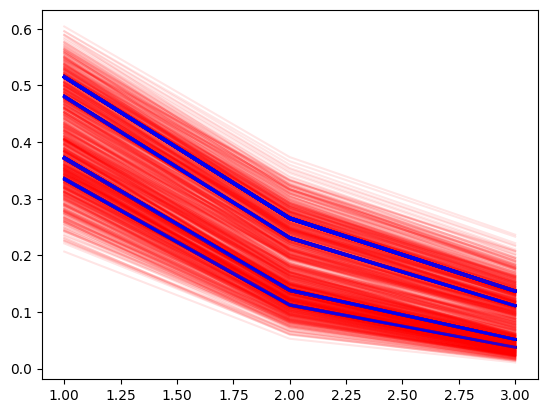

In [24]:
sv_ave = sv_prob["sv"].mean(0)
N = sv_ave.shape[0]
# tttimes = np.unique(y_sk["Survival_in_days"])
tttimes = np.unique(trn["x"][:,0])

# Do for the first 10
for i in range(0,N):
    plt.plot(tttimes, sv_ave[i,:], color = "red", alpha =0.1)
    plt.plot(tttimes[:], sv_scale_true["sv_true"][i,:], color = "blue", alpha =0.2)
    # sv_scale_true["sv_true"].shape

Additionally, metrics like RMSE can be derived against the True Survival

In [25]:
rmse = np.sqrt((np.power((sv_ave - sv_scale_true["sv_true"]),2)).sum(0)/N)
print("RMSE")
[print(r) for r in rmse]

RMSE
0.04996985189983181
0.03576376031592299
0.024221871324935


[None, None, None]

Additional evaluations like the Hazard Ratio (as Risk Ratio) and Marginal Distribution Effects can be derived to further evaluate a variables impact on the outcome.

This is completed through Partial Dependence Functions. Simply explained, PD functions are evaluations of the model with conterfactual type data. 

If examining the first covariate, a counterfactual dataset with the variable set to its opposite value is derived and passed through the `sample_posterior_predictive` to return posterior predictions used to evaluate the marginal effects.

- `get_pdp()`
  - generates the pdp dataset
  - key parameters
    - `var_col` 
      - covariate column selected 
      - can be upto 2 variables
    - `values`
      - list of lists counterfactual values
  

In [42]:
pdp1 = sb.get_pdp(x_mat, var_col = [0], values = [[0,1]], sample_n = None)
# pdp_tst = sb.get_posterior_test(event_dict[""], pdp1[0])


pdp_tst = sb.get_posterior_test(
    y_time=event_dict["t_event"], 
    y_status=event_dict["status"],
    x = pdp1[0],
    time_scale=60
)

pdp_post = BSM.sample_posterior_predictive(pdp_tst["post_x"], pdp_tst["coords"])

0.19928601491078082
Starting predict ...
Processing: 6000 observations, 2000 thinned draws (Thin factor: 1)...


In [43]:
pdp_sv_prob = sb.get_sv_prob(pdp_post, coords=pdp_tst["coords"])
# pdp_sv_prob datasets are N*values in length

Risk Ratio can be derived by dividing the probabiltiy prediction given var=1/var=0 (or however the pdp function was defined). More accurately this would be a risk ratio at discrete time points and a Hazard Ratio when averaged across time points. 

With continuous values, values can be selected as the standard unit increase of the variable (age=21/age=20). 

Or moving away from a direct HR interpretation, broader range of values could be selected such as "age=60/age=20".

Care must be taken when reporting on these metrics so they are not confused with the conditional hazard ratios defined by other Survival methods like the Cox-Proportional Hazard models.

To recover Hazard Ratios equivalent to a model the the CPH, the Complementary Log-Log (Clog-log) adjustment must be used.

The Problem: Proportional Hazards vs. Relative RiskThe Cox model assumes Proportional Hazards, meaning the ratio of the underlying continuous hazard rates between two groups is constant over time. However, discrete probabilities do not scale linearly with continuous rates. As the baseline risk increases (or if you use wider time bins), a simple ratio of probabilities (Relative Risk) will artificially shrink towards 1.0, making the BART estimates appear biased when compared directly to a Cox Hazard Ratio (HR).

The Solution: The Clog-log LinkTo ensure a "fair fight" between the models, we must mathematically recover the underlying continuous rate from our discrete probabilities. If we assume the continuous hazard rate ($h$) is constant within a specific discrete time interval, the probability ($p$) of an event occurring in that interval is:$$p = 1 - \exp(-h)$$By rearranging this equation, we can use the Complementary Log-Log (Clog-log) transformation to translate the BART probabilities back into continuous hazard rates:$$h = -\ln(1 - p)$$Why we use it here:By applying h = -np.log(1 - p) to the marginal BART predictions before calculating the ratio, we achieve two things:
    Methodological Parity: We generate a true Rate-Adjusted Hazard Ratio that is directly comparable to the standard output of a Cox model.
    Coarsening Robustness: The estimates become highly robust to the n_time_bins parameter. Even if the time grid is relatively coarse, the log-log mathematics naturally correct for the discretization of the timeline.

In [46]:
# 1. Get the average probabilities for the treated and untreated groups
msk_1 = pdp1[1]["coord"] == 1
p1 = pdp_sv_prob["prob"][:, msk_1, :].mean(axis=1)
p0 = pdp_sv_prob["prob"][:, ~msk_1, :].mean(axis=1)

# 2. Apply the Clog-log transformation to recover the hazard rates
h1 = -np.log(1 - p1)
h0 = -np.log(1 - p0)

# 3. Calculate the Rate-Adjusted Hazard Ratio
HR = (h1 / h0).mean(axis=0)
print(HR)
print(np.exp(-.4))

[0.68205425 0.68333211 0.58785874]
0.6703200460356393


In [ ]:
#  Comparison to the RR
msk_1 = pdp1[1]["coord"] == 1
RR = (pdp_sv_prob["prob"][:,msk_1,:].mean(1) / pdp_sv_prob["prob"][:,~msk_1,:].mean(1)).mean(0)
HR = RR.mean()


print(RR)
print(HR)
print(np.exp(-.4)) # Expected HR

[0.78876605 0.78516057 0.72310835]
0.7656783217030649
0.6703200460356393


The RR can be interpreted as the ratio of the cumulative probability of an event occurring by a specific point in time. RR is useful to describe risk at a meaningful milestone.
The HR can be interpreted as the ratio of the instantaneous probability of an event occurring at that point in time. HR can be used to describe effectiveness over the whole period.

Repeating the process for the other variables parameterized in `scale_f`

In [49]:
HR_L = []
RR_L = []
for i in range(0,5):
    pdp1 = sb.get_pdp(x_mat, var_col = [i], values = [[0,1]], sample_n = 100)
    # pdp_tst = sb.get_posterior_test(y_sk, pdp1[0])

    pdp_tst = sb.get_posterior_test(
        y_time=event_dict["t_event"], 
        y_status=event_dict["status"],
        x = pdp1[0],
        time_scale=60
    )

    pdp_post = BSM.sample_posterior_predictive(pdp_tst["post_x"], pdp_tst["coords"])
    pdp_sv_prob = sb.get_sv_prob(pdp_post, pdp_tst["coords"])
    msk_1 = pdp1[1]["coord"] == 1
    #RR
    RR = (pdp_sv_prob["prob"][:,msk_1,:].mean(1) / pdp_sv_prob["prob"][:,~msk_1,:].mean(1)).mean(0)
    RR_L.append(RR.mean())
    #HR
    HR = (np.log(1-(pdp_sv_prob["prob"][:,msk_1,:].mean(1))) / np.log(1-pdp_sv_prob["prob"][:,~msk_1,:].mean(1))).mean(0)
    HR_L.append(HR.mean())

0.19928601491078082
Starting predict ...
Processing: 600 observations, 2000 thinned draws (Thin factor: 1)...
0.19928601491078082
Starting predict ...
Processing: 600 observations, 2000 thinned draws (Thin factor: 1)...
0.19928601491078082
Starting predict ...
Processing: 600 observations, 2000 thinned draws (Thin factor: 1)...
0.19928601491078082
Starting predict ...
Processing: 600 observations, 2000 thinned draws (Thin factor: 1)...
0.19928601491078082
Starting predict ...
Processing: 600 observations, 2000 thinned draws (Thin factor: 1)...


In [50]:
# Using the orignal scale_f equation, the True HR can be dreived
# np.exp(4 + .4*x_mat[:,0] + .1*x_mat[:,1] + .01*x_mat[:,2])", # note that x_mat[:,3] and x_mat[:,4] are not included

print(f"x0 true {np.exp(-.4)} : pred HR {HR_L[0]}, RR {RR_L[0]}")
print(f"x1 true {np.exp(-.1)} : pred HR {HR_L[1]}, RR {RR_L[1]}")
print(f"x2 true {np.exp(-.01)} : pred HR {HR_L[2]}, RR {RR_L[2]}")
print(f"x2 true {np.exp(0)} : pred HR {HR_L[3]}, RR {RR_L[3]}")
print(f"x2 true {np.exp(-0)} : pred HR {HR_L[4]},  RR {RR_L[4]}")


x0 true 0.6703200460356393 : pred HR 0.653109114315897, RR 0.765965754934269
x1 true 0.9048374180359595 : pred HR 0.8703270352079188, RR 0.9182068491055465
x2 true 0.9900498337491681 : pred HR 1.221700076462105, RR 1.1259635806757977
x2 true 1.0 : pred HR 0.9685436533530547, RR 0.9700801947078883
x2 true 1.0 : pred HR 1.2028907640943665,  RR 1.1068952214500365


## Cox Proportional Hazard Model
As a comparison, the simulated data can be analyzed with a Cox Proportional Hazard Model.

In [47]:
# !pip install scikit-survival

In [51]:
from sksurv import linear_model
import lifelines as ll
import pandas as pd

In [33]:

# reformat the data into a pandas dataframe
tmp = np.hstack([
    x_mat, 
    event_dict["t_event"].reshape(-1,1), 
    event_dict["status"].reshape(-1,1)]
    )
pdf = pd.DataFrame(tmp)
pdf.columns = ["x1", "x2", "x3", "x4", "x5", "t", "s"]
print(pdf.head())

    x1   x2     x3        x4        x5      t    s
0  1.0  1.0  0.284  0.115267  0.688936  180.0  0.0
1  1.0  0.0  0.010  0.878597  0.531591   26.0  1.0
2  0.0  0.0  0.110  0.299339  0.742602  132.0  1.0
3  1.0  1.0  0.131  0.745929  0.897600  180.0  0.0
4  0.0  1.0  0.432  0.937366  0.457821   28.0  1.0


In [52]:
CPH = ll.CoxPHFitter()
# Fit the model 
CPH.fit(pdf, duration_col = "t", event_col = "s", formula = "x1 + x2 + x3 +x4 +x5")
CPH.summary

,coef,exp(coef),se(coef),coef lower 95%,coef upper 95%,exp(coef) lower 95%,exp(coef) upper 95%,cmp to,z,p,-log2(p)
covariate,,,,,,,,,,,
x1,-0.402192,0.668852,0.066729,-0.532979,-0.271405,0.586854,0.762308,0.0,-6.027220,1.668044e-09,29.159196
x2,-0.180313,0.835009,0.073093,-0.323572,-0.037053,0.723560,0.963625,0.0,-2.466902,1.362877e-02,6.197201
x3,0.192339,1.212082,0.111975,-0.027127,0.411806,0.973237,1.509542,0.0,1.717702,8.585091e-02,3.542023
x4,-0.082356,0.920944,0.113571,-0.304952,0.140240,0.737159,1.150550,0.0,-0.725148,4.683614e-01,1.094306
x5,0.230433,1.259145,0.117603,-0.000065,0.460931,0.999935,1.585549,0.0,1.959412,5.006459e-02,4.320066


The predicted Survival probabilites can also be collected and compared to the True Sv probabilites.

In [51]:
# cph_surv.shape
sv_true["sv_true"]
# CPH.timeline.shape

array([[0.98898364, 0.97808864, 0.96731366, ..., 0.13920696, 0.13767341,
        0.13615675],
       [0.98779893, 0.97574673, 0.96384158, ..., 0.11246109, 0.11108895,
        0.10973354],
       [0.98187084, 0.96407035, 0.94659257, ..., 0.03851916, 0.03782084,
        0.03713518],
       ...,
       [0.98365201, 0.96757127, 0.95175343, ..., 0.05318436, 0.05231491,
        0.05145966],
       [0.98781129, 0.97577115, 0.96387777, ..., 0.1127119 , 0.11133809,
        0.10998102],
       [0.98895303, 0.9780281 , 0.96722385, ..., 0.13844218, 0.13691281,
        0.13540034]])

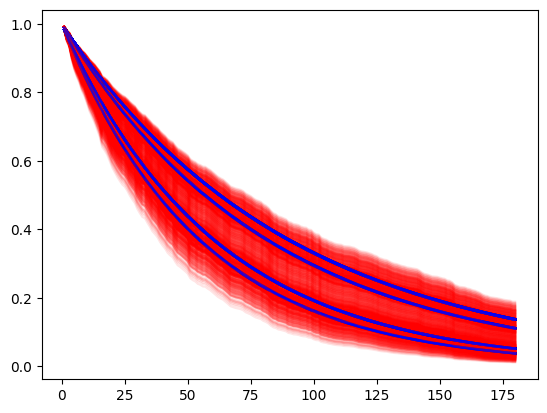

In [53]:
# Display predicted values against the True Values
cph_surv = CPH.predict_survival_function(pdf).T.to_numpy()
for i in range(0,N):
    plt.plot(CPH.timeline, cph_surv[i,:], color = "red", alpha =0.1)
    plt.plot(sv_true["true_times"], sv_true["sv_true"][i,:], color = "blue", alpha =0.2)
    # sv_scale_true["sv_true"].shape

Notably these predictions at baseline are not falling into the range of the True values.

Examination of the hazard ratios in comparison with the True HR can be made.

In [54]:
cph_hr = CPH.hazard_ratios_.to_numpy()
print("CPH HR")
print(f"x0 true {np.exp(-.4)} : pred {cph_hr[0]}")
print(f"x1 true {np.exp(-.1)} : pred {cph_hr[1]}")
print(f"x2 true {np.exp(-.01)} : pred {cph_hr[2]}")
print(f"x2 true {np.exp(0)} : pred {cph_hr[3]}")
print(f"x2 true {np.exp(-0)} : pred {cph_hr[4]}")

print("\n BART HR")
print(f"x0 true {np.exp(-.4)} : pred {HR_L[0]}")
print(f"x1 true {np.exp(-.1)} : pred {HR_L[1]}")
print(f"x2 true {np.exp(-.01)} : pred {HR_L[2]}")
print(f"x2 true {np.exp(0)} : pred {HR_L[3]}")
print(f"x2 true {np.exp(-0)} : pred {HR_L[4]}")


CPH HR
x0 true 0.6703200460356393 : pred 0.6688522218027529
x1 true 0.9048374180359595 : pred 0.8350091909535303
x2 true 0.9900498337491681 : pred 1.2120818762571135
x2 true 1.0 : pred 0.9209440548864128
x2 true 1.0 : pred 1.2591450246548264

 BART HR
x0 true 0.6703200460356393 : pred 0.653109114315897
x1 true 0.9048374180359595 : pred 0.8703270352079188
x2 true 0.9900498337491681 : pred 1.221700076462105
x2 true 1.0 : pred 0.9685436533530547
x2 true 1.0 : pred 1.2028907640943665
